# Alzheimer MRI Classification with Swin Transformer

This notebook uses a safer Swin pipeline with:
- duplicate-aware train/validation splitting
- repeated-slice audit on the test set
- patient-group evaluation inferred from filenames
- only the most useful plots for model review


In [1]:
import importlib

import swin_alzheimer_pipeline as pipeline

pipeline = importlib.reload(pipeline)

TrainingConfig = pipeline.TrainingConfig
plot_dataset_distribution = pipeline.plot_dataset_distribution
plot_training_curves = pipeline.plot_training_curves
print_test_metrics = pipeline.print_test_metrics
print_classification_report = pipeline.print_classification_report
plot_per_class_metrics = pipeline.plot_per_class_metrics
plot_confusion_matrix_from_results = pipeline.plot_confusion_matrix_from_results
plot_roc_curves_from_results = pipeline.plot_roc_curves_from_results
plot_precision_recall_curves_from_results = pipeline.plot_precision_recall_curves_from_results
refresh_test_evaluation = pipeline.refresh_test_evaluation
run_experiment = pipeline.run_experiment

C:\Users\akpan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
config = TrainingConfig(
    model_name="swin_tiny_patch4_window7_224",
    img_size=224,
    batch_size=16,
    epochs=10,
    val_size=0.15,
    backbone_lr=2e-5,
    head_lr=1e-4,
    weight_decay=1e-4,
    label_smoothing=0.08,
    drop_rate=0.2,
    drop_path_rate=0.2,
    random_erasing_prob=0.15,
    use_weighted_sampler=True,
    sampler_power=0.5,
    class_weight_power=0.5,
    freeze_backbone_epochs=1,
    gradient_clip_norm=1.0,
    early_stopping_patience=5,
    reduce_lr_patience=2,
    split_by_hash_groups=True,
    deduplicate_train=True,
    audit_dataset=True,
    seed=42,
)

config

TrainingConfig(train_dir='Dataset/Training Set', test_dir='Dataset/Testing Set', model_name='swin_tiny_patch4_window7_224', img_size=224, batch_size=16, epochs=10, val_size=0.15, backbone_lr=2e-05, head_lr=0.0001, weight_decay=0.0001, label_smoothing=0.08, drop_rate=0.2, drop_path_rate=0.2, random_erasing_prob=0.15, use_weighted_sampler=True, sampler_power=0.5, class_weight_power=0.5, freeze_backbone_epochs=1, gradient_clip_norm=1.0, early_stopping_patience=5, reduce_lr_patience=2, split_by_hash_groups=True, deduplicate_train=True, audit_dataset=True, seed=42, num_workers=0)

## Train and Evaluate

Run the next cell to train the Swin model, restore the best checkpoint, and evaluate on the test set.

If you already trained and only want to recompute the test evaluation after changing the pipeline, use:

```python
results = refresh_test_evaluation(results)
test_results = results["test_results"]
```

In [3]:
results = run_experiment(config)
test_results = results["test_results"]

Using device: cuda
Config:
  train_dir: Dataset/Training Set
  test_dir: Dataset/Testing Set
  model_name: swin_tiny_patch4_window7_224
  img_size: 224
  batch_size: 16
  epochs: 10
  val_size: 0.15
  backbone_lr: 2e-05
  head_lr: 0.0001
  weight_decay: 0.0001
  label_smoothing: 0.08
  drop_rate: 0.2
  drop_path_rate: 0.2
  random_erasing_prob: 0.15
  use_weighted_sampler: True
  sampler_power: 0.5
  class_weight_power: 0.5
  freeze_backbone_epochs: 1
  gradient_clip_norm: 1.0
  early_stopping_patience: 5
  reduce_lr_patience: 2
  split_by_hash_groups: True
  deduplicate_train: True
  audit_dataset: True
  seed: 42
  num_workers: 0


Class distribution
------------------------------------------------------------
Class                   Train      Val     Test
------------------------------------------------------------
MildDemented             7506     1324      896
ModerateDemented         5227      922       64
NonDemented              8146     1438     3200
VeryMildDemented         7602     1341     2240
------------------------------------------------------------
Dataset audit
------------------------------------------------------------
Train duplicate groups: 195
Redundant duplicate train files: 462
Cross-class duplicate groups: 0
Exact train/val hash overlap after split: 0
Exact train/test hash overlap: 0
Train samples used after split: 28481
Validation samples used after split: 5025
------------------------------------------------------------
Test patient-group audit (inferred from filename)
------------------------------------------------------------
Class                  Images   Patients   Repeat   Mean/

Model loaded successfully
Backbone parameters: 27,519,354
Head parameters: 3,076
Backbone frozen for the first 1 epoch(s).


Epoch 01/10 | train_loss=1.2979 | train_acc=0.4007 | val_loss=1.1919 | val_acc=0.5232 | val_macro_f1=0.4913 | val_macro_auc=0.7852
Backbone unfrozen. Fine-tuning the full network.


Epoch 02/10 | train_loss=0.8536 | train_acc=0.6703 | val_loss=0.7543 | val_acc=0.7477 | val_macro_f1=0.7414 | val_macro_auc=0.9431


...

Epoch 06/10 | train_loss=0.4093 | train_acc=0.9466 | val_loss=0.3443 | val_acc=0.9803 | val_macro_f1=0.9821 | val_macro_auc=0.9994


Epoch 07/10 | train_loss=0.3812 | train_acc=0.9601 | val_loss=0.3459 | val_acc=0.9791 | val_macro_f1=0.9808 | val_macro_auc=0.9990


Epoch 08/10 | train_loss=0.3620 | train_acc=0.9696 | val_loss=0.3171 | val_acc=0.9916 | val_macro_f1=0.9924 | val_macro_auc=0.9998


Epoch 09/10 | train_loss=0.3532 | train_acc=0.9742 | val_loss=0.3077 | val_acc=0.9970 | val_macro_f1=0.9973 | val_macro_auc=1.0000


Epoch 10/10 | train_loss=0.3417 | train_acc=0.9796 | val_loss=0.3095 | val_acc=0.9956 | val_macro_f1=0.9960 | val_macro_auc=0.9998
Best checkpoint restored from epoch 9.


## Dataset Distribution

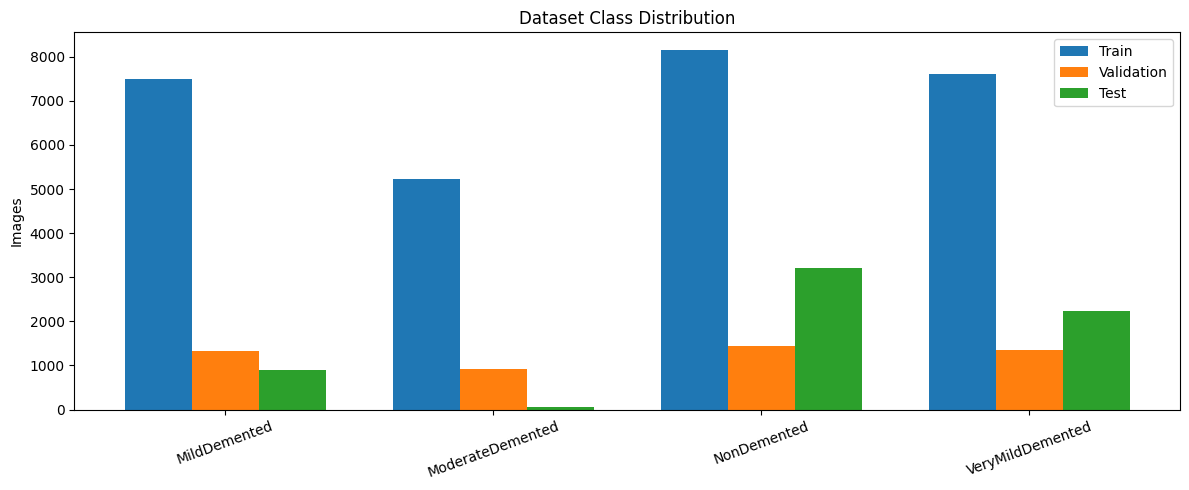

In [4]:
plot_dataset_distribution(
    results["class_names"],
    results["train_counts"],
    results["val_counts"],
    results["test_counts"],
)

## Training Curves

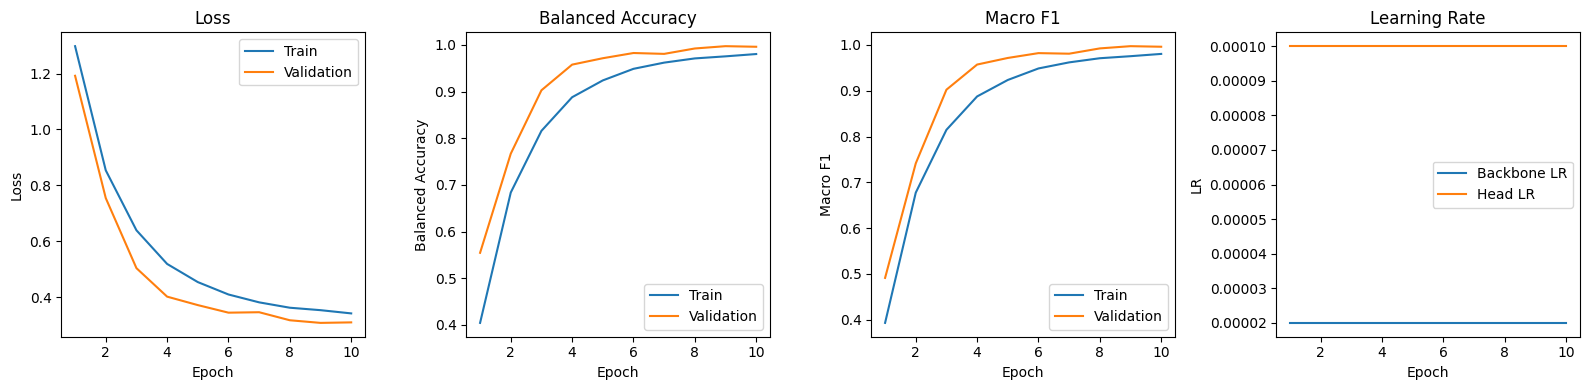

In [5]:
plot_training_curves(results["history"])

## Test Metrics

In [6]:
print(f"Best validation selection score: {results['best_score']:.4f} (epoch {results['best_epoch']})")
print_test_metrics(test_results)
print_classification_report(test_results)

Best validation selection score: 0.9981 (epoch 9)
Image-level test metrics
Test loss: 0.0899
Accuracy: 0.9897
Balanced accuracy: 0.9936
Macro F1: 0.9904
Weighted F1: 0.9897
Macro precision: 0.9874
Macro recall: 0.9936
Macro ROC-AUC (OvR): 0.9999
Macro Average Precision: 0.9998

Patient-level test metrics (slice probabilities averaged per inferred patient)
Patients evaluated: 5148
Multi-slice patients: 27
Max slices for one patient: 100
Inconsistent label groups: 0
Accuracy: 0.9922
Balanced accuracy: 0.9956
Macro F1: 0.9932
Weighted F1: 0.9922
Macro precision: 0.9909
Macro recall: 0.9956
Macro ROC-AUC (OvR): 0.9999
Macro Average Precision: 0.9999
Image-level classification report
                  precision    recall  f1-score   support

    MildDemented       0.96      1.00      0.98       896
ModerateDemented       1.00      1.00      1.00        64
     NonDemented       0.99      0.99      0.99      3200
VeryMildDemented       0.99      0.98      0.99      2240

        accuracy    

## Per-Class Metrics

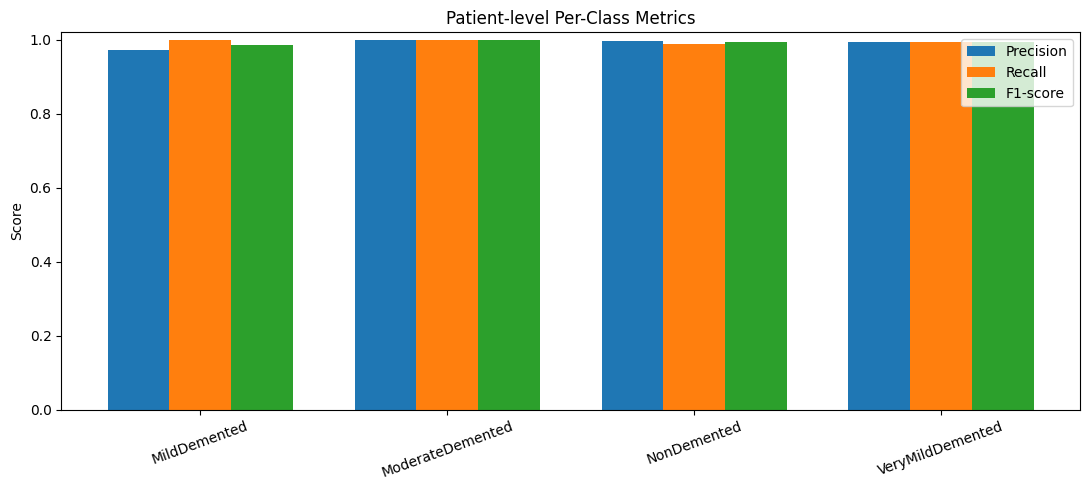

In [7]:
plot_per_class_metrics(test_results, results["class_names"], level="patient")

## Confusion Matrices

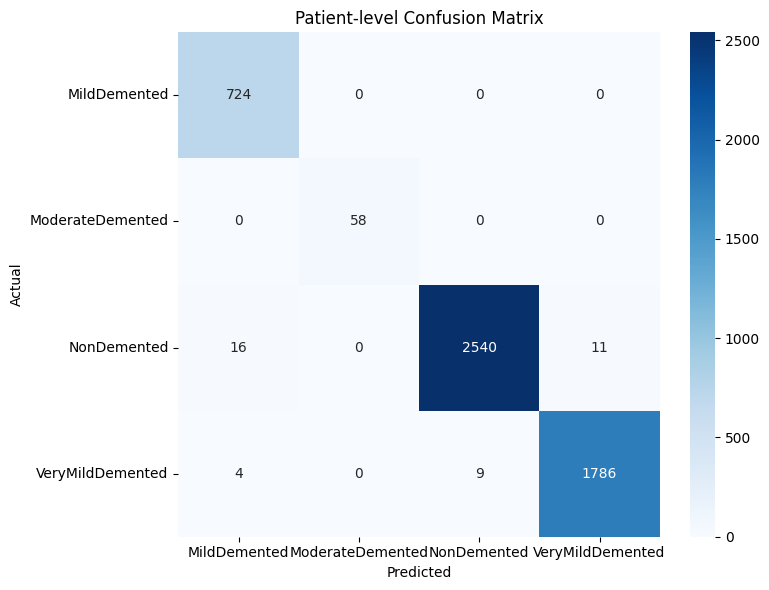

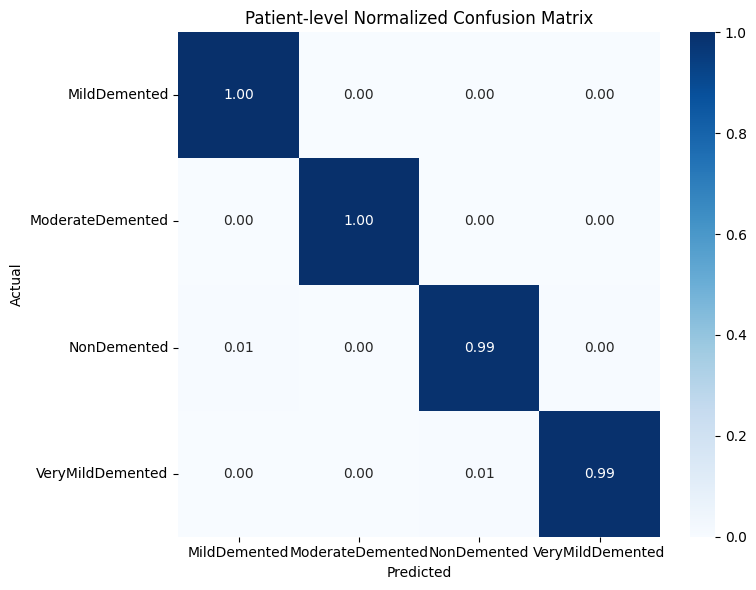

In [8]:
plot_confusion_matrix_from_results(test_results, results["class_names"], normalize=False, level="patient")
plot_confusion_matrix_from_results(test_results, results["class_names"], normalize=True, level="patient")

## ROC Curves

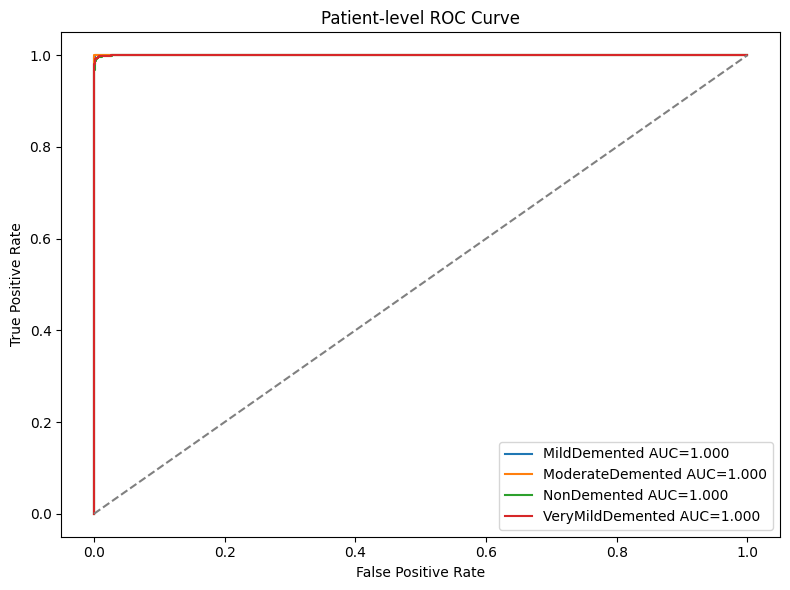

{'per_class_auc': {0: 0.9999871994045537,
  1: 1.0,
  2: 0.9998003147570715,
  3: 0.9999103712274379},
 'macro_auc': 0.9999244713472658,
 'level': 'Patient-level'}

In [9]:
roc_summary = plot_roc_curves_from_results(test_results, results["class_names"], level="patient")
roc_summary

## Precision-Recall Curves

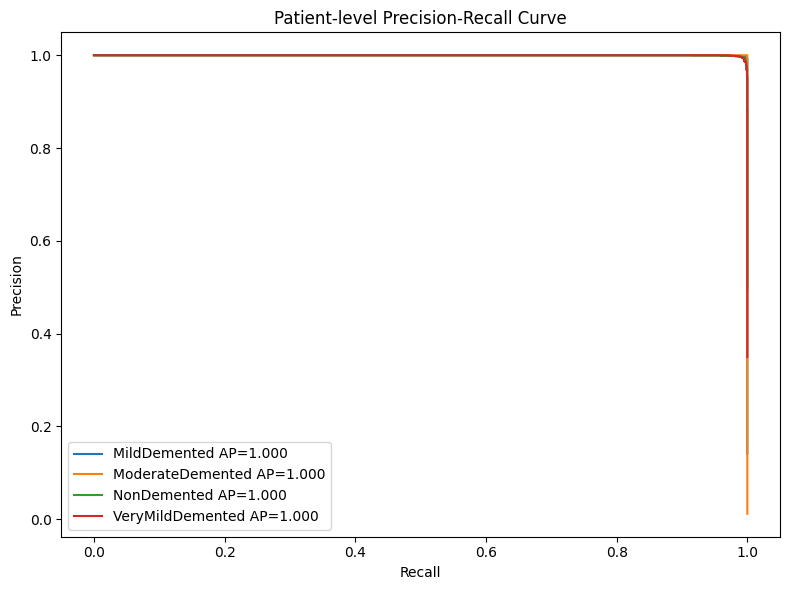

{'per_class_average_precision': {0: 0.9999208437160104,
  1: 1.0,
  2: 0.9998041619818384,
  3: 0.9998356730394207},
 'macro_average_precision': 0.9998901696843173,
 'level': 'Patient-level'}

: 

In [ ]:
pr_summary = plot_precision_recall_curves_from_results(test_results, results["class_names"], level="patient")
pr_summary